# Glacier Album: EIC Messages and Source Data

Issue #8. This notebook follows [docs/notebook-guide.md](../docs/notebook-guide.md). For each ice-related visualization in NASA's [Earth Information Center (EIC)](https://svs.gsfc.nasa.gov/gallery/earth-information-center/), it:

1. reads what EIC says,
2. loads the original data behind it,
3. reproduces the graph EIC shows and checks EIC's numbers,
4. prepares the data series that can become tracks on the album.

Run it with `npm run notebook`. Downloads are cached in `notebooks/.cache/` (git-ignored).

The sea level section needs a free [NASA Earthdata](https://urs.earthdata.nasa.gov/users/new) login in `~/.netrc` (see the guide). Without it, that section is skipped.

In [1]:
import html
import json
import netrc
import re
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

CACHE = Path(".cache")
CACHE.mkdir(exist_ok=True)


def cached(name, url, session=None):
    """Download url into the cache once and return the local path."""
    path = CACHE / name
    if not path.exists():
        response = (session or requests).get(url, timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)
    return path


def svs_page(page_id):
    return json.loads(cached(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return html.unescape(re.sub(r"<[^>]+>", "", text or "")).strip()


def credit(ax, text):
    ax.annotate(text, xy=(0, -0.22), xycoords="axes fraction", fontsize=8, color="gray")


(CACHE / "api").mkdir(exist_ok=True)

## 1. EIC pages and messages

The ice-related EIC visualizations, what each one says in EIC's own words, and the data it is built from. The ids come from crawling the EIC gallery for ice terms in titles and SVS keywords.

In [2]:
PAGES = {
    5046: "Daily Arctic Sea Ice, By Year",
    5064: "Daily Antarctic Sea Ice, By Year",
    5099: "Daily Polar Sea Ice, Two Year History",
    5382: "Arctic Sea Ice Minimum 2024",
    5235: "Sea Level Through a Porthole (2023)",
    14713: "Building Coastal Resilience with NASA Data",
}


def page_row(page_id):
    page = svs_page(page_id)
    # The page description is the message; when it is only a heading, use the longest media caption.
    message = plain(page["description"].split(" || ")[0])
    if len(message) < 100:
        texts = [plain(g.get("caption")) or plain(g.get("description")) for g in page["media_groups"]]
        message = max(texts, key=len)
    datasets = "; ".join(f"{d['name']} ({d.get('sensor') or d.get('platform')})" for d in page.get("datasets", []))
    return {"id": page_id, "title": page["title"], "released": page["release_date"][:10],
            "message (EIC text)": message[:400], "source data (SVS)": datasets or "-"}


pages = pd.DataFrame([page_row(i) for i in PAGES])
pages

,id,title,released,message (EIC text),source data (SVS)
0,5046,"Daily Arctic Sea Ice, By Year",2022-11-28,"This visualization shows the daily Arctic sea ice and seasonal land cover change progressing through time, with a si...",Blue Marble: Next Generation (MODIS); 10 km Daily Sea Ice Concentration (AMSR2); 10 km Daily 89 GHz Brightness Tempe...
1,5064,"Daily Antarctic Sea Ice, By Year",2023-01-17,"This visualization shows the daily Antarctic sea ice and seasonal land cover change progressing through time, with a...",Blue Marble: Next Generation (MODIS); 10 km Daily Sea Ice Concentration (AMSR2); 10 km Daily 89 GHz Brightness Tempe...
2,5099,"Daily Polar Sea Ice, Two Year History",2023-05-01,This visualization shows the daily Arctic and Antarctic sea ice and seasonal land cover change over a two-year histo...,Blue Marble: Next Generation (MODIS); 10 km Daily Sea Ice Concentration (AMSR2); 10 km Daily 89 GHz Brightness Tempe...
3,5382,Arctic Sea Ice Minimum 2024,2024-09-24,Satellite-based passive microwave images of the sea ice have provided a reliable tool for continuously monitoring ch...,Blue Marble: Next Generation (MODIS); 10 km Daily Sea Ice Concentration (AMSR2); 10 km Daily 89 GHz Brightness Tempe...
4,5235,Sea Level Through a Porthole (2023),2024-03-21,"As the planet warms and polar ice melts, our global average sea level is rising. Although exact ocean heights vary d...","Global Mean Sea Level (TOPEX/Poseidon, Jason-1, OSTM/Jason-2, and Jason-3)"
5,14713,Building Coastal Resilience with NASA Data,2025-01-07,"The city of Mobile, AL is working with NASA’s Sea Level Change Team to plan for future infrastructure projects and t...",-


**What EIC is saying, in short:**

| EIC page | Message | Source data |
| --- | --- | --- |
| 5046, 5064, 5099 | Polar sea ice grows and shrinks every day, through the seasons, at both poles | JAXA AMSR2 sea ice concentration |
| 5382 | Every summer Arctic ice melts to a minimum. In 2024 it reached 4.28 million km² on Sept 11, the 7th lowest on record since 1979, inside the 1981–2010 average minimum (yellow line) | JAXA AMSR2, numbers from NASA and NSIDC |
| 5235 | "As the planet warms and polar ice melts, our global average sea level is rising", 1993–2023 | NASA GSFC Global Mean Sea Level (TOPEX/Poseidon, Jason-1/2/3, Sentinel-6) |
| 14713 | Coastal cities face more storms and floods, and use NASA sea level data to plan a resilient future | Produced video, message only |

Together they form one story, which follows EIC's own aim of helping people see change, understand why it matters, and respond:

1. **Breathing**: the poles freeze and thaw every year (5046, 5064, 5099).
2. **Loss**: the Arctic now melts below the old normal (5382).
3. **Consequence**: melting ice raises the sea (5235).
4. **Response**: people on the coast adapt (14713).

## 2. Source data: sea ice extent

The EIC sea ice images are drawn from JAXA's AMSR2 10 km daily sea ice concentration grids, which need a JAXA G-Portal account. The numbers EIC quotes come from the **NSIDC Sea Ice Index (G02135, version 4.0)**, which NASA and NSIDC use for their yearly minimum announcements. Its recent daily values are computed from the same AMSR2 sensor, so we use it.

- **Extent**: total area of ocean with at least 15% ice cover, in million km²
- **Daily** values from Oct 1978 to now (every other day before Aug 1987)
- **Climatology**: average and percentiles per day of year over 1981–2010, the "normal" EIC compares against

Credit: Fetterer, F., et al. Sea Ice Index, Version 4. NSIDC, doi:10.7265/a98x-0f50.

In [3]:
NSIDC = "https://noaadata.apps.nsidc.org/NOAA/G02135"
POLE = {"N": "north", "S": "south"}


def sea_ice_daily(hemisphere):
    name = f"{hemisphere}_seaice_extent_daily_v4.0.csv"
    path = cached(name, f"{NSIDC}/{POLE[hemisphere]}/daily/data/{name}")
    df = pd.read_csv(path, skiprows=[1], skipinitialspace=True, usecols=[0, 1, 2, 3])
    df.columns = ["year", "month", "day", "extent"]
    df["date"] = pd.to_datetime(df[["year", "month", "day"]])
    # Fill single missing days (every other day before 1987) so rolling averages work.
    return df.set_index("date")["extent"].asfreq("D").interpolate(limit=2)


def sea_ice_normal(hemisphere):
    name = f"{hemisphere}_seaice_extent_climatology_1981-2010_v4.0.csv"
    path = cached(name, f"{NSIDC}/{POLE[hemisphere]}/daily/data/{name}")
    df = pd.read_csv(path, skiprows=1, skipinitialspace=True)
    df.columns = ["doy", "mean", "std", "p10", "p25", "p50", "p75", "p90"]
    return df.set_index("doy")


ice = {h: sea_ice_daily(h) for h in "NS"}
normal = {h: sea_ice_normal(h) for h in "NS"}
print({h: f"{s.index.min().date()} to {s.index.max().date()}, {s.notna().sum()} days" for h, s in ice.items()})

{'N': '1978-10-26 to 2026-11-12, 17511 days', 'S': '1978-10-26 to 2026-11-12, 17511 days'}


## 3. Message 1, breathing: the poles freeze and thaw every year

> "This visualization shows the daily Arctic sea ice and seasonal land cover change progressing through time, with a single frame rendered for each day." (EIC 5046; 5064 and 5099 say the same for the Antarctic and both poles)

The EIC pages show 2021 to 2024, one year per video, and the last two years side by side for both poles. The graph below draws the same years from the source data, against the 1981–2010 normal.

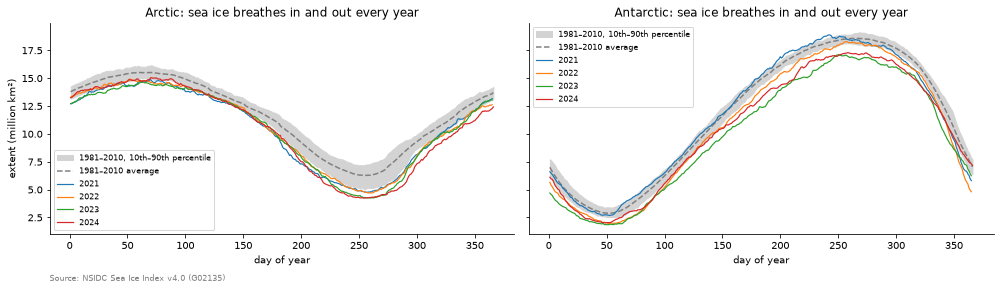

In [4]:
YEARS = [2021, 2022, 2023, 2024]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (h, label) in zip(axes, [("N", "Arctic"), ("S", "Antarctic")]):
    norm = normal[h]
    ax.fill_between(norm.index, norm["p10"], norm["p90"], color="lightgray", label="1981–2010, 10th–90th percentile")
    ax.plot(norm.index, norm["mean"], color="gray", linestyle="--", label="1981–2010 average")
    for year in YEARS:
        s = ice[h][str(year)]
        ax.plot(s.index.day_of_year, s.values, linewidth=1.2, label=str(year))
    ax.set_title(f"{label}: sea ice breathes in and out every year")
    ax.set_xlabel("day of year")
    ax.legend(fontsize=8)
axes[0].set_ylabel("extent (million km²)")
credit(axes[0], "Source: NSIDC Sea Ice Index v4.0 (G02135)")
plt.tight_layout()

In [5]:
def yearly_cycle(h):
    f5 = ice[h].rolling(5).mean()  # NSIDC reports minima and maxima on a 5-day trailing average
    g = f5[f5.index.year.isin(YEARS)].groupby(f5[f5.index.year.isin(YEARS)].index.year)
    out = pd.DataFrame({"max": g.max(), "max date": g.idxmax().dt.strftime("%b %d"),
                        "min": g.min(), "min date": g.idxmin().dt.strftime("%b %d")})
    out["breath (max - min)"] = out["max"] - out["min"]
    return out.round(2)


pd.concat({"Arctic": yearly_cycle("N"), "Antarctic": yearly_cycle("S")})

max max date   min min date  breath (max - min)
          date                                                   
Arctic    2021  14.78   Mar 12  4.77   Sep 16               10.01
          2022  14.84   Feb 25  4.70   Sep 19               10.14
          2023  14.62   Mar 06  4.26   Sep 19               10.36
          2024  15.02   Mar 14  4.25   Sep 14               10.77
Antarctic 2021  18.84   Sep 01  2.70   Feb 24               16.14
          2022  18.25   Sep 16  1.98   Feb 25               16.27
          2023  17.07   Sep 09  1.85   Feb 21               15.21
          2024  17.26   Sep 16  2.03   Feb 20               15.23

What the data says:

- Each year the Arctic swings by about 10 million km² and the Antarctic by 15 to 16 million km².
- The poles breathe in **opposite phase**: the Arctic peaks in March and bottoms out in September, the Antarctic the other way round.
- 2021 to 2024 look alike. Over four years the seasonal cycle dominates; the long-term decline is not visible at this scale. EIC does not claim a decline in these pages either.

**Track data**: daily extent per pole per year (365 values), or the last two years with both poles together, as in 5099.

## 4. Message 2, loss: the Arctic melts below the old normal

> "Every summer the Arctic ice cap melts down to what scientists call its 'minimum' before colder weather begins to cause ice cover to increase. [...] the 2024 minimum extent, which was likely reached on Sept. 11, measured 1.65 million square miles (4.28 million square kilometers). This is the 7th lowest measured sea ice extent for the arctic on record. [...] The yellow boundary shows the minimum extent averaged over the 30-year period from 1981 to 2010." (EIC 5382)

The animation runs from the 2024 maximum (March 14) to the minimum (Sept 11).

Gap to the 1981–2010 average: 0.46 million km² on Mar 14, 2.01 on Sep 11, largest 2.17


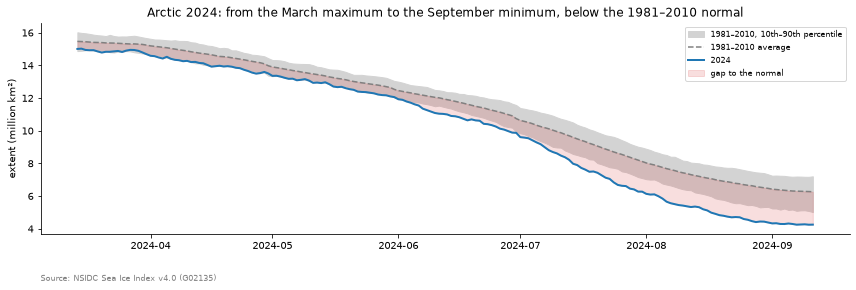

In [6]:
melt = ice["N"]["2024-03-14":"2024-09-11"]
norm = normal["N"].loc[melt.index.day_of_year]
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.fill_between(melt.index, norm["p10"], norm["p90"], color="lightgray", label="1981–2010, 10th–90th percentile")
ax.plot(melt.index, norm["mean"].values, color="gray", linestyle="--", label="1981–2010 average")
ax.plot(melt.index, melt.values, color="tab:blue", linewidth=2, label="2024")
ax.fill_between(melt.index, melt.values, norm["mean"].values, color="tab:red", alpha=0.15, label="gap to the normal")
ax.set_title("Arctic 2024: from the March maximum to the September minimum, below the 1981–2010 normal")
ax.set_ylabel("extent (million km²)")
ax.legend(fontsize=8)
credit(ax, "Source: NSIDC Sea Ice Index v4.0 (G02135)")
plt.tight_layout()

gap = norm["mean"].values - melt.values
print(f"Gap to the 1981–2010 average: {gap[0]:.2f} million km² on Mar 14, {gap[-1]:.2f} on Sep 11, largest {gap.max():.2f}")

,"EIC (5382, Sept 2024)",NSIDC v4.0 (this notebook)
2024 minimum,4.28 million km²,4.25 million km²
date,Sept 11,Sep 14
rank since 1979,7th lowest,6th lowest


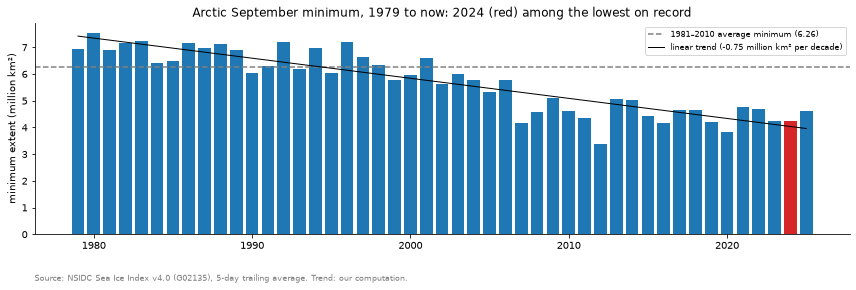

In [7]:
f5 = ice["N"].rolling(5).mean()
minima = f5.groupby(f5.index.year).agg(["min", "idxmin"])
minima = minima[(minima.index >= 1979) & (minima.index < pd.Timestamp.now().year)]
minima.columns = ["minimum", "date"]
minima["rank (1 = lowest)"] = minima["minimum"].rank().astype(int)
normal_min = normal["N"]["mean"].min()

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(minima.index, minima["minimum"], color=["tab:red" if y == 2024 else "tab:blue" for y in minima.index])
ax.axhline(normal_min, color="gray", linestyle="--", label=f"1981–2010 average minimum ({normal_min:.2f})")
trend = np.polyfit(minima.index, minima["minimum"], 1)
ax.plot(minima.index, np.polyval(trend, minima.index), color="black", linewidth=1,
        label=f"linear trend ({trend[0] * 10:+.2f} million km² per decade)")
ax.set_title("Arctic September minimum, 1979 to now: 2024 (red) among the lowest on record")
ax.set_ylabel("minimum extent (million km²)")
ax.legend(fontsize=8)
credit(ax, "Source: NSIDC Sea Ice Index v4.0 (G02135), 5-day trailing average. Trend: our computation.")
plt.tight_layout()

check = pd.DataFrame({
    "EIC (5382, Sept 2024)": ["4.28 million km²", "Sept 11", "7th lowest"],
    "NSIDC v4.0 (this notebook)": [f"{minima.loc[2024, 'minimum']:.2f} million km²",
                                   minima.loc[2024, "date"].strftime("%b %d"),
                                   f"{minima.loc[2024, 'rank (1 = lowest)']}th lowest"],
}, index=["2024 minimum", "date", "rank since 1979"])
check

What the data says:

- 2024 stays below the 1981–2010 normal for the whole melt season, and the gap widens toward September.
- The September minimum has fallen since 1979 (the trend line is our addition, not an EIC claim).
- Our numbers differ slightly from EIC's because NSIDC reprocessed the Sea Ice Index (version 4.0) after the September 2024 announcement. The message is the same: 2024 is one of the lowest years on record.

**Track data**: the 2024 melt (Mar 14 to Sep 11, 182 days) together with the normal for the same days, so the gap between them can be heard. Or the yearly minimum since 1979 (one value per year) as a slow descending line.

## 5. Message 3, consequence: melting ice raises the sea

> "As the planet warms and polar ice melts, our global average sea level is rising. [...] These visualizations use the visual metaphor of a submerged porthole window to observe how far our oceans rose between 1993 and 2023." (EIC 5235)
>
> "The blue mark on the ruler shows the exact measurements [...]. The level of the animated water changes more smoothly, driven by a 60-day floating average of the same data."

Source: **Global Mean Sea Level (GMSL), version 5.2**, NASA Goddard Space Flight Center, from the Integrated Multi-Mission Ocean Altimeter Data (TOPEX/Poseidon, Jason-1, Jason-2, Jason-3, Sentinel-6). One value about every 10 days, in mm relative to a 20-year mean. Hosted by [PO.DAAC](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V52); downloading it needs an Earthdata login.

In [8]:
GMSL_URL = ("https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/"
            "MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V52/GMSL_TPJAOS_5.2.txt")
GMSL_COLUMNS = ["altimeter", "cycle", "year", "n_obs", "n_weighted",
                "gmsl", "gmsl_std", "gmsl_smooth",
                "gmsl_gia", "gmsl_gia_std", "gmsl_gia_smooth", "gmsl_gia_smooth_no_season"]


def has_earthdata_login():
    try:
        return netrc.netrc().authenticators("urs.earthdata.nasa.gov") is not None
    except (FileNotFoundError, netrc.NetrcParseError):
        return False


gmsl = None
if (CACHE / "GMSL_TPJAOS_5.2.txt").exists() or has_earthdata_login():
    # requests reads ~/.netrc and re-applies it on the redirect to urs.earthdata.nasa.gov.
    path = cached("GMSL_TPJAOS_5.2.txt", GMSL_URL, session=requests.Session())
    rows = [line.split() for line in path.read_text().splitlines() if line.strip() and not line.startswith("HDR")]
    gmsl = pd.DataFrame(rows, columns=GMSL_COLUMNS).astype(float)
    gmsl["date"] = pd.to_datetime("1993-01-01") + pd.to_timedelta((gmsl["year"] - 1993) * 365.25, unit="D")
    print(f"GMSL: {len(gmsl)} values, {gmsl['date'].min().date()} to {gmsl['date'].max().date()}")
else:
    print("Skipped: no Earthdata login in ~/.netrc. See docs/notebook-guide.md.")

Skipped: no Earthdata login in ~/.netrc. See docs/notebook-guide.md.


In [9]:
if gmsl is not None:
    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.plot(gmsl["date"], gmsl["gmsl_gia"], ".", markersize=2, color="tab:blue", alpha=0.4, label="measurements (blue mark)")
    ax.plot(gmsl["date"], gmsl["gmsl_gia_smooth"], color="tab:blue", linewidth=1.5, label="60-day smoothed (animated water)")
    ax.axvspan(pd.Timestamp("1993-01-01"), pd.Timestamp("2023-12-31"), color="lightgray", alpha=0.3, label="period shown by EIC")
    ax.set_title("Global mean sea level keeps rising as polar ice melts and oceans warm")
    ax.set_ylabel("sea level variation (mm)")
    ax.legend(fontsize=8)
    credit(ax, "Source: NASA GSFC Global Mean Sea Level v5.2 (PO.DAAC), GIA applied")
    plt.tight_layout()

    period = gmsl[(gmsl["date"] >= "1993-01-01") & (gmsl["date"] <= "2023-12-31")].set_index("date")["gmsl_gia_smooth"]
    rise = period.iloc[-12:].mean() - period.iloc[:12].mean()
    rate = np.polyfit(gmsl["year"], gmsl["gmsl_gia"], 2)
    print(f"Rise from 1993 to 2023 (smoothed): about {rise:.0f} mm")
    print(f"Rate today (quadratic fit, our computation): {np.polyval(np.polyder(rate), gmsl['year'].iloc[-1]):.1f} mm/year")

What the data says (once loaded):

- How far the sea rose from 1993 to 2023, and how fast it rises today (the rate is our computation), printed above.
- The raw measurements wobble around the smoothed line; EIC shows both, the exact mark and the smooth water.

**Track data**: the smoothed series (one value about every 10 days, 1993 to now) as a slowly rising floor, with the raw measurements as a ripple on top.

Message 4 (response, EIC 14713) is a produced video with no data of its own. Its imagery may not be remixed, so the album uses its message only.

## 6. Message summary

In [10]:
summary = pd.DataFrame([
    {"message": "Breathing: the poles freeze and thaw every year", "EIC pages": "5046, 5064, 5099",
     "key numbers": f"yearly swing about {yearly_cycle('N')['breath (max - min)'].mean():.0f} (Arctic) and "
                    f"{yearly_cycle('S')['breath (max - min)'].mean():.0f} (Antarctic) million km², opposite phases",
     "source": "NSIDC Sea Ice Index v4.0"},
    {"message": "Loss: the Arctic melts below the old normal", "EIC pages": "5382",
     "key numbers": f"2024 minimum {minima.loc[2024, 'minimum']:.2f} million km², "
                    f"{minima.loc[2024, 'rank (1 = lowest)']}th lowest since 1979; normal minimum {normal_min:.2f}",
     "source": "NSIDC Sea Ice Index v4.0"},
    {"message": "Consequence: melting ice raises the sea", "EIC pages": "5235",
     "key numbers": "needs an Earthdata login" if gmsl is None else f"{rise:.0f} mm from 1993 to 2023",
     "source": "NASA GSFC GMSL v5.2"},
    {"message": "Response: coastal cities adapt", "EIC pages": "14713",
     "key numbers": "-", "source": "message only"},
])
summary

,message,EIC pages,key numbers,source
0,Breathing: the poles freeze and thaw every year,"5046, 5064, 5099","yearly swing about 10 (Arctic) and 16 (Antarctic) million km², opposite phases",NSIDC Sea Ice Index v4.0
1,Loss: the Arctic melts below the old normal,5382,"2024 minimum 4.25 million km², 6th lowest since 1979; normal minimum 6.26",NSIDC Sea Ice Index v4.0
2,Consequence: melting ice raises the sea,5235,needs an Earthdata login,NASA GSFC GMSL v5.2
3,Response: coastal cities adapt,14713,-,message only


## 7. Track candidates

The data series each message offers. Length is the number of values; the album decides how fast to play them.

In [11]:
def describe(name, message, series, unit):
    series = series.dropna()
    return {"track candidate": name, "message": message, "values": len(series),
            "from": series.index.min().date(), "to": series.index.max().date(),
            "min": round(series.min(), 2), "max": round(series.max(), 2), "unit": unit}


tracks = [describe(f"Arctic {y}", "breathing", ice["N"][str(y)], "million km²") for y in YEARS]
tracks += [describe(f"Antarctic {y}", "breathing", ice["S"][str(y)], "million km²") for y in YEARS]
for h, label in [("N", "Arctic"), ("S", "Antarctic")]:
    recent = ice[h][ice[h].index.max() - pd.DateOffset(years=2):]
    tracks.append(describe(f"{label}, last two years (pair with the other pole)", "breathing", recent, "million km²"))
tracks.append(describe("Arctic melt 2024 (Mar 14 to Sep 11)", "loss", melt, "million km²"))
tracks.append(describe("Arctic September minimum since 1979", "loss",
                       minima.set_index(pd.to_datetime(minima.index.astype(str)))["minimum"], "million km²"))
if gmsl is not None:
    tracks.append(describe("Global mean sea level since 1993", "consequence", gmsl.set_index("date")["gmsl_gia_smooth"], "mm"))
pd.DataFrame(tracks)

,track candidate,message,values,from,to,min,max,unit
0,Arctic 2021,breathing,365,2021-01-01,2021-12-31,4.76,14.86,million km²
1,Arctic 2022,breathing,365,2022-01-01,2022-12-31,4.69,14.94,million km²
2,Arctic 2023,breathing,365,2023-01-01,2023-12-31,4.24,14.64,million km²
3,Arctic 2024,breathing,366,2024-01-01,2024-12-31,4.24,15.04,million km²
4,Antarctic 2021,breathing,365,2021-01-01,2021-12-31,2.68,18.89,million km²
5,Antarctic 2022,breathing,365,2022-01-01,2022-12-31,1.96,18.28,million km²
6,Antarctic 2023,breathing,365,2023-01-01,2023-12-31,1.85,17.11,million km²
7,Antarctic 2024,breathing,366,2024-01-01,2024-12-31,2.02,17.28,million km²
8,"Arctic, last two years (pair with the other pole)",breathing,731,2024-11-12,2026-11-12,4.54,14.36,million km²
9,"Antarctic, last two years (pair with the other pole)",breathing,731,2024-11-12,2026-11-12,1.96,17.85,million km²


## Next steps

- Choose the tracks and their order (for example: breathing, loss, consequence, response).
- Decide how each series maps to sound, and how fast each track plays.
- Export the chosen series into `src/features/<feature>/data/` with their source, credit and message (see the guide).